# 18 · Rolling window (E46)

All earlier results use 5-fold CV grouped by brand, which mixes months. Here the final model is trained only on posts from earlier months and tested on the next month (2026-05 … 2026-08), as Brand24 would use it. Same test posts for every scheme:
- **brand CV**: the usual out-of-fold number;
- **expanding**: train on all months before M;
- **expanding, new brands**: as above without the test month's brands;
- **sliding**: train on month M-1 only.

Final model: CatBoost MAE on followers + reactions + missing flags. MAE of log10(views), paired brand bootstrap CI.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import history as H, rolling_window as rw

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)

In [2]:
f, meta = rw.load(ROOT)

## 1 · Posts per month and drift
Views per like is the ratio the model mostly learns; if it moves between months, a model trained on the past is off.

In [3]:
D = rw.drift(meta); D.pivot(index="month", columns="platform", values=["posts", "median_views_per_like"]).round(3)

posts                 median_views_per_like                
platform tiktok twitter youtube                tiktok twitter youtube
month                                                                
2026-04   310.0    73.0   236.0                 1.371   1.230   1.557
2026-05   540.0   441.0   425.0                 1.397   1.146   1.568
2026-06   500.0   374.0   435.0                 1.391   1.342   1.540
2026-07   521.0   480.0   554.0                 1.372   1.301   1.301
2026-08   388.0   390.0   586.0                 1.335   1.230   1.126

## 2 · Error per month and scheme

In [4]:
P = rw.run(f, meta); T = rw.by_month(P)
T.pivot_table(index=["platform", "month"], columns="model", values="MAE", sort=False)[rw.SCHEMES].round(3)

model             brand CV  expanding  expanding, new brands  sliding (previous month)
platform month                                                                        
tiktok   2026-05     0.272      0.280                  0.280                     0.296
         2026-06     0.279      0.274                  0.281                     0.279
         2026-07     0.265      0.266                  0.266                     0.275
         2026-08     0.272      0.270                  0.270                     0.289
youtube  2026-05     0.459      0.485                  0.492                     0.490
         2026-06     0.464      0.468                  0.472                     0.490
         2026-07     0.442      0.458                  0.460                     0.477
         2026-08     0.427      0.427                  0.433                     0.430
twitter  2026-05     0.480      0.552                  0.533                     0.551
         2026-06     0.445      0.465                  0.453                     0.482
         2026-07     0.459      0.466                  0.470                     0.473
         2026-08     0.472      0.476                  0.483                     0.476

In [5]:
S = H.summarise(P); S.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,brand CV,1949,0.272,0.260,0.284,-0.016
1,tiktok,expanding,1949,0.273,0.261,0.286,-0.009
2,tiktok,"expanding, new brands",1949,0.274,0.263,0.288,-0.012
3,tiktok,sliding (previous month),1949,0.285,0.273,0.298,-0.009
4,youtube,brand CV,2000,0.446,0.422,0.472,-0.025
5,youtube,expanding,2000,0.457,0.432,0.485,0.024
6,youtube,"expanding, new brands",2000,0.461,0.435,0.487,0.014
7,youtube,sliding (previous month),2000,0.469,0.442,0.499,-0.037
8,twitter,brand CV,1685,0.464,0.448,0.484,-0.046
9,twitter,expanding,1685,0.491,0.471,0.510,-0.060


In [6]:
G = pd.DataFrame([{"platform": p, "comparison": f"brand CV -> {k}", **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P, p, "brand CV", k)))} for p in rw.PLATS for k in rw.SCHEMES[1:]]); G.round(3)

,platform,comparison,gain,CI low,CI high
0,tiktok,brand CV -> expanding,-0.001,-0.004,0.002
1,tiktok,"brand CV -> expanding, new brands",-0.003,-0.005,0.000
2,tiktok,brand CV -> sliding (previous month),-0.013,-0.019,-0.007
3,youtube,brand CV -> expanding,-0.011,-0.018,-0.004
4,youtube,"brand CV -> expanding, new brands",-0.016,-0.023,-0.007
5,youtube,brand CV -> sliding (previous month),-0.023,-0.032,-0.015
6,twitter,brand CV -> expanding,-0.026,-0.036,-0.017
7,twitter,"brand CV -> expanding, new brands",-0.021,-0.030,-0.014
8,twitter,brand CV -> sliding (previous month),-0.032,-0.042,-0.022


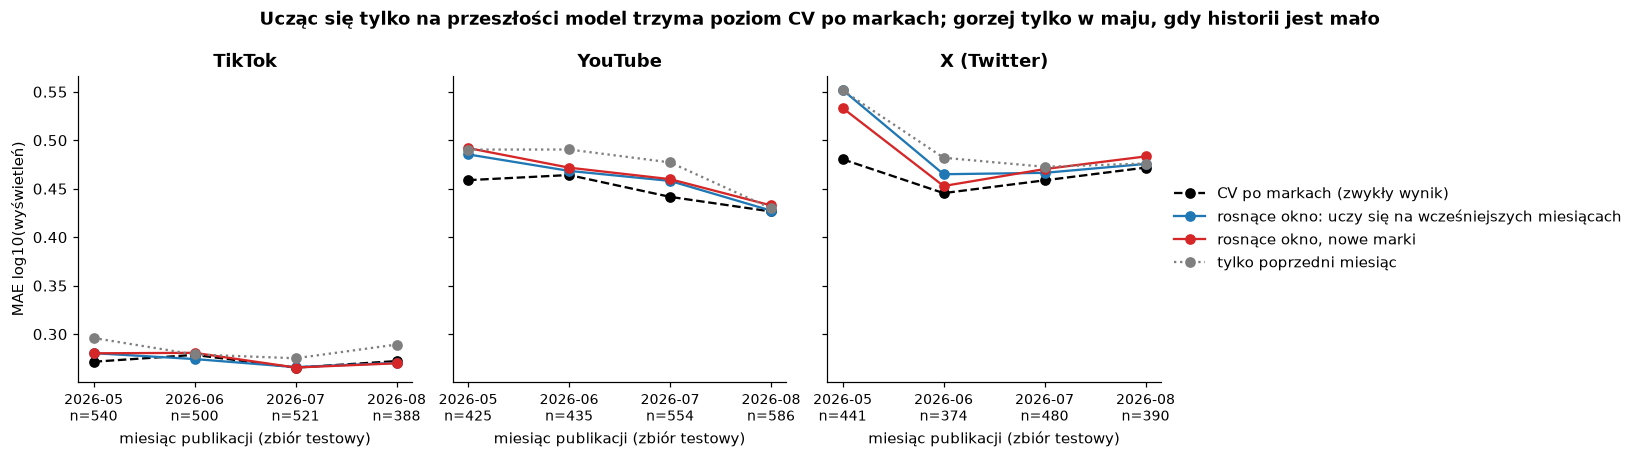

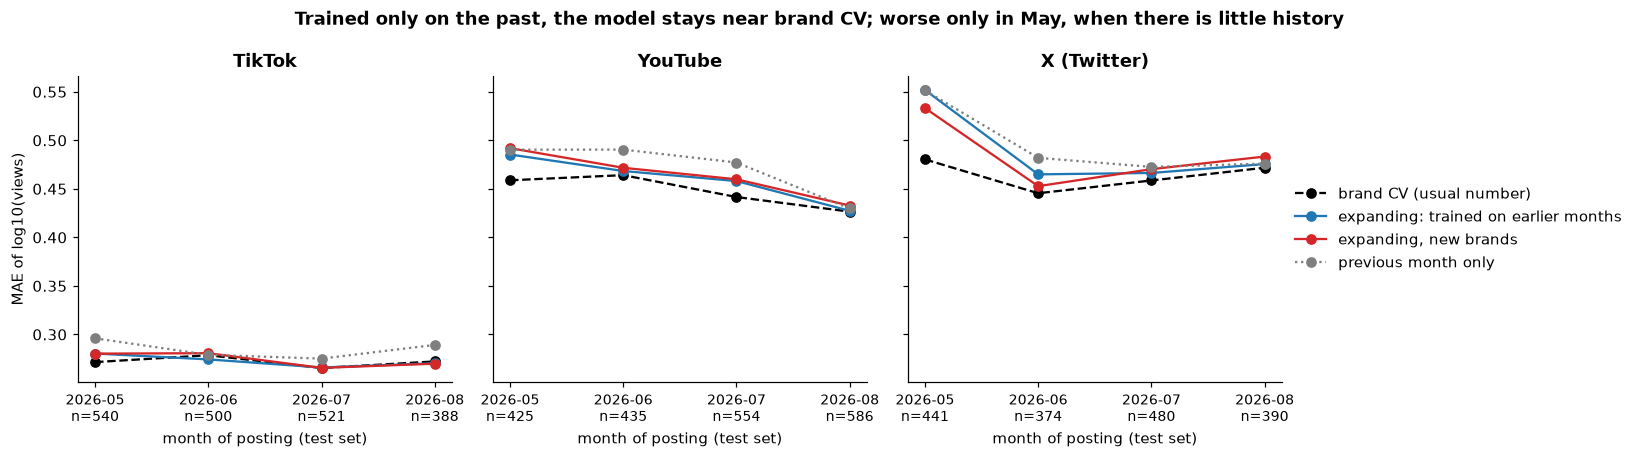

In [7]:
for l in ("pl", "en"): rw.plot(T, FIG / f"rolling_window_{l}.png", l)

## Takeaways
See `docs/en/experiments.md` (E46) and `agent/vault/E46.md`. Numbers: `data/processed/rolling_window_numbers.json`.

In [8]:
json.dump({"drift": D.to_dict("records"), "by_month": T.to_dict("records"), "overall": S.to_dict("records"), "gains": G.to_dict("records")},
          open(ROOT / "data" / "processed" / "rolling_window_numbers.json", "w"), indent=1, default=float)